In [1]:
# Libraries and analysis settings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Preprocessing
from sklearn.preprocessing import StandardScaler

# Unsupervised learning
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Supervised learning models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# Cross-validation and pipelines
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

# Additional clustering and model evaluation
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from sklearn.utils.class_weight import compute_sample_weight

# Optional clustering method (available in recent scikit-learn versions)
try:
    from sklearn.cluster import HDBSCAN
except ImportError:
    HDBSCAN = None

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from IPython.display import display

# Display and plot settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

import joblib  # Export fitted model for Streamlit


In [2]:
# Load the five MOM industry-level datasets (2026Q2 release).
# Keep these five CSV files in the same folder as this notebook.
df_employment = pd.read_csv("employment change.csv")
df_vacancy = pd.read_csv("job vacancy rate.csv")
df_recruitment = pd.read_csv("recruitment rate.csv")
df_resignation = pd.read_csv("resignation rate.csv")
df_retrenchment = pd.read_csv("retrench.csv")

# Check required industry-level structure and latest available quarter.
for name, data in {
    "Employment Change": df_employment,
    "Job Vacancy Rate": df_vacancy,
    "Recruitment Rate": df_recruitment,
    "Resignation Rate": df_resignation,
    "Retrenchment": df_retrenchment,
}.items():
    assert "industry" in data.columns or name == "Employment Change", f"{name} is not industry-level"
    assert data["quarter"].max() >= "2026-Q2", f"{name} does not reach 2026Q2"
    print(f"{name}: {len(data):,} rows, latest quarter {data['quarter'].max()}")


Employment Change: 4,274 rows, latest quarter 2026-Q2
Job Vacancy Rate: 4,700 rows, latest quarter 2026-Q2
Recruitment Rate: 4,700 rows, latest quarter 2026-Q2
Resignation Rate: 4,700 rows, latest quarter 2026-Q2
Retrenchment: 4,700 rows, latest quarter 2026-Q2


# Singapore Sectoral Labour Market Stress Monitor

**Capstone analysis | 31 October 2026**

This notebook examines quarterly industry-level labour market conditions in Singapore using five Ministry of Manpower (MOM) indicators. The data preparation and feature engineering stages are followed by two distinct analyses:

1. **Historical analysis:** PCA and K-Means clustering identify descriptive labour market states, with comparisons against GMM and HDBSCAN and a separate examination of observed quarter-to-quarter transitions.
2. **Next-quarter screening:** An analyst-defined stress label supports chronological validation and comparison of supervised classification models.

The three historical cluster labels and the stress criteria are analytical definitions, not official MOM classifications. Historical transition rates are descriptive and are not used as the supervised learning target. The notebook also prepares data and model exports for the Streamlit dashboard.

## 1. Data understanding and preparation


In [3]:
# Check shape and column names of each dataset
datasets = {
    "Job Vacancy Rate": df_vacancy,
    "Recruitment Rate": df_recruitment,
    "Resignation Rate": df_resignation,
    "Employment Change": df_employment,
    "Retrenchment": df_retrenchment
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())



Job Vacancy Rate
Shape: (4700, 3)
Columns: ['quarter', 'industry', 'job_vacancy_rate']

Recruitment Rate
Shape: (4700, 3)
Columns: ['quarter', 'industry', 'recruitment_rate']

Resignation Rate
Shape: (4700, 3)
Columns: ['quarter', 'industry', 'resignation_rate']

Employment Change
Shape: (4274, 11)
Columns: ['quarter', 'industry1', 'industry2', 'industry3', 'employment_change', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10']

Retrenchment
Shape: (4700, 3)
Columns: ['quarter', 'industry', 'retrench']


In [4]:
# Remove unnamed empty columns from employment dataset
df_employment = df_employment.loc[
    :, ~df_employment.columns.str.contains("^Unnamed")
]

df_employment.head()


,quarter,industry1,industry2,industry3,employment_change
0,1991-Q1,manufacturing,"food, beverages and tobacco","food, beverages and tobacco",0.1
1,1991-Q1,manufacturing,textile and wearing apparel,textile and wearing apparel,-1
2,1991-Q1,manufacturing,paper products and publishing,paper products and publishing,0.1
3,1991-Q1,manufacturing,"petroleum, chemical, rubber and plastic products","petroleum, chemical, rubber and plastic products",0.3
4,1991-Q1,manufacturing,fabricated metal products,fabricated metal products,0.2


In [5]:
#Check data types and missing values
for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 50)
    df.info()
    print("\nMissing values:")
    print(df.isnull().sum())



Job Vacancy Rate
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4700 entries, 0 to 4699
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   quarter           4700 non-null   object
 1   industry          4700 non-null   object
 2   job_vacancy_rate  4700 non-null   object
dtypes: object(3)
memory usage: 110.3+ KB

Missing values:
quarter             0
industry            0
job_vacancy_rate    0
dtype: int64

Recruitment Rate
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4700 entries, 0 to 4699
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   quarter           4700 non-null   object 
 1   industry          4700 non-null   object 
 2   recruitment_rate  4700 non-null   float64
dtypes: float64(1), object(2)
memory usage: 110

In [6]:
#Find values that cannot be converted into numbers
value_columns = {
    "Job Vacancy Rate": (df_vacancy, "job_vacancy_rate"),
    "Recruitment Rate": (df_recruitment, "recruitment_rate"),
    "Resignation Rate": (df_resignation, "resignation_rate"),
    "Employment Change": (df_employment, "employment_change"),
    "Retrenchment": (df_retrenchment, "retrench")
}

for name, (df, column) in value_columns.items():

    non_numeric = df[
        pd.to_numeric(df[column], errors="coerce").isna()
        & df[column].notna()
    ][column].value_counts()

    print(f"\n{name}")

    if non_numeric.empty:
        print("None")
    else:
        print(non_numeric.rename_axis(None).rename(None))



Job Vacancy Rate
-    23
dtype: int64

Recruitment Rate
None

Resignation Rate
None

Employment Change
-       221
n.a.     66
dtype: int64

Retrenchment
-    605
dtype: int64


In [7]:
# Convert MOM notation to appropriate numeric values
df_vacancy["job_vacancy_rate"] = (
    df_vacancy["job_vacancy_rate"]
    .replace("-", 0)
    .astype(float)
)

df_employment["employment_change"] = (
    df_employment["employment_change"]
    .replace({"-": 0, "n.a.": np.nan})
    .astype(float)
)

df_retrenchment["retrench"] = (
    df_retrenchment["retrench"]
    .replace("-", 0)
    .astype(float)
)


/tmp/ipykernel_2116/1450326226.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_employment["employment_change"] = (


In [8]:
# Check whether the employment industry structure changes over time
industry_count = (
    df_employment
    .groupby("quarter")
    .size()

    .reset_index(name="industry_rows")
)

industry_count.groupby("industry_rows").agg(
    first_quarter=("quarter", "min"),
    last_quarter=("quarter", "max"),
    number_of_quarters=("quarter", "count")
)


,first_quarter,last_quarter,number_of_quarters
industry_rows,,,
23,1991-Q1,2001-Q4,44
32,2026-Q2,2026-Q2,1
33,2009-Q1,2025-Q4,68
34,2002-Q1,2026-Q1,29


### Harmonise industry classifications
Employment Change requires aggregation to the 12 broad industries shared by the five datasets.


In [9]:
# Keep employment data from 2009 onwards
df_employment = df_employment[
    df_employment["quarter"] >= "2009-Q1"
].copy()


In [10]:
# Create broad industry category
df_employment["industry"] = df_employment["industry2"]

df_employment.loc[
    df_employment["industry1"] == "manufacturing",
    "industry"
] = "manufacturing"


Manufacturing is aggregated from its component industries; the other broad industry categories are retained.


In [11]:
# Aggregate employment change to the 12 broad industry groups
df_employment_broad = (
    df_employment
    .groupby(["quarter", "industry"], as_index=False)["employment_change"]
    .sum(min_count=1)
)


In [12]:
# Define the 12 common broad industries for harmonisation
broad_industries = [
    "manufacturing",
    "construction",
    "wholesale and retail trade",
    "transportation and storage",
    "accommodation and food services",
    "information and communications",
    "financial and insurance services",
    "real estate services",
    "professional services",
    "administrative and support services",
    "community, social and personal services",
    "others"
]

# Check that all 12 broad industries are available in each dataset
industry_datasets = {
    "Job Vacancy Rate": df_vacancy,
    "Recruitment Rate": df_recruitment,
    "Resignation Rate": df_resignation,
    "Retrenchment": df_retrenchment
}

for name, df in industry_datasets.items():
    missing_industries = [
        industry for industry in broad_industries
        if industry not in df["industry"].values
    ]

    print(f"{name}: {len(missing_industries)} missing industries")


Job Vacancy Rate: 0 missing industries
Recruitment Rate: 0 missing industries
Resignation Rate: 0 missing industries
Retrenchment: 0 missing industries


In [13]:
# Filter remaining datasets to the common period and 12 broad industries
df_vacancy_broad = df_vacancy[
    (df_vacancy["quarter"] >= "2009-Q1") &
    (df_vacancy["industry"].isin(broad_industries))
].copy()

# Filter Recruitment Rate
df_recruitment_broad = df_recruitment[
    (df_recruitment["quarter"] >= "2009-Q1") &
    (df_recruitment["industry"].isin(broad_industries))
].copy()

# Filter Resignation Rate
df_resignation_broad = df_resignation[
    (df_resignation["quarter"] >= "2009-Q1") &
    (df_resignation["industry"].isin(broad_industries))
].copy()

# Filter Retrenchment
df_retrenchment_broad = df_retrenchment[
    (df_retrenchment["quarter"] >= "2009-Q1") &
    (df_retrenchment["industry"].isin(broad_industries))
].copy()


### Build the master dataset


In [14]:
# Validate dimensions of the five harmonised datasets before merging
broad_datasets = {
    "Employment Change": df_employment_broad,
    "Job Vacancy Rate": df_vacancy_broad,
    "Recruitment Rate": df_recruitment_broad,
    "Resignation Rate": df_resignation_broad,
    "Retrenchment": df_retrenchment_broad
}

for name, df in broad_datasets.items():
    print(
        name,
        "| Shape:", df.shape,
        "| Quarters:", df["quarter"].nunique(),
        "| Industries:", df["industry"].nunique()
    )


Employment Change | Shape: (840, 3) | Quarters: 70 | Industries: 12
Job Vacancy Rate | Shape: (840, 3) | Quarters: 70 | Industries: 12
Recruitment Rate | Shape: (840, 3) | Quarters: 70 | Industries: 12
Resignation Rate | Shape: (840, 3) | Quarters: 70 | Industries: 12
Retrenchment | Shape: (840, 3) | Quarters: 70 | Industries: 12


In [15]:
# Start with employment change
df_master = df_employment_broad.copy()

# Merge the remaining indicators
df_master = df_master.merge(
    df_vacancy_broad,
    on=["quarter", "industry"],
    how="inner"
)

df_master = df_master.merge(
    df_recruitment_broad,
    on=["quarter", "industry"],
    how="inner"
)

df_master = df_master.merge(
    df_resignation_broad,
    on=["quarter", "industry"],
    how="inner"
)

df_master = df_master.merge(
    df_retrenchment_broad,
    on=["quarter", "industry"],
    how="inner"
)


In [16]:
# Convert quarter to quarterly period format
df_master["quarter"] = pd.PeriodIndex(
    df_master["quarter"],
    freq="Q"
)

# Sort chronologically within each industry
df_master = (
    df_master
    .sort_values(["industry", "quarter"])
    .reset_index(drop=True)
)

df_master.head()


,quarter,industry,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
0,2009Q1,accommodation and food services,-2.7,1.0,2.9,3.7,40.0
1,2009Q2,accommodation and food services,-1.6,1.6,3.6,4.0,90.0
2,2009Q3,accommodation and food services,0.4,3.6,4.1,4.0,10.0
3,2009Q4,accommodation and food services,6.1,3.2,4.5,3.7,60.0
4,2010Q1,accommodation and food services,2.8,3.9,4.1,4.2,60.0


In [17]:
#Final integrity check
print("Missing values:")
print(df_master.isna().sum())

print("\nDuplicate quarter-industry rows:")
print(df_master.duplicated(subset=["quarter", "industry"]).sum())

print("\nQuarters:", df_master["quarter"].nunique())
print("Industries:", df_master["industry"].nunique())

print("\nPeriod:", df_master["quarter"].min(), "to", df_master["quarter"].max())


Missing values:
quarter              0
industry             0
employment_change    0
job_vacancy_rate     0
recruitment_rate     0
resignation_rate     0
retrench             0
dtype: int64

Duplicate quarter-industry rows:
0

Quarters: 70
Industries: 12

Period: 2009Q1 to 2026Q2


## 2. Exploratory data analysis


In [18]:
# Define the five labour-market indicators
indicators = [
    "employment_change",
    "job_vacancy_rate",
    "recruitment_rate",
    "resignation_rate",
    "retrench"
]

# Summary statistics
df_master[indicators].describe().round(2)


,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
count,840.00,840.00,840.00,840.00,840.00
mean,1.42,3.11,2.47,1.88,287.21
std,4.43,1.36,1.01,0.90,456.22
min,-27.80,0.40,0.50,0.40,0.00
25%,-0.20,2.20,1.70,1.30,40.00
50%,1.10,2.90,2.20,1.60,160.00
75%,2.90,3.90,3.00,2.20,400.00
max,31.60,10.20,5.70,4.90,9100.00


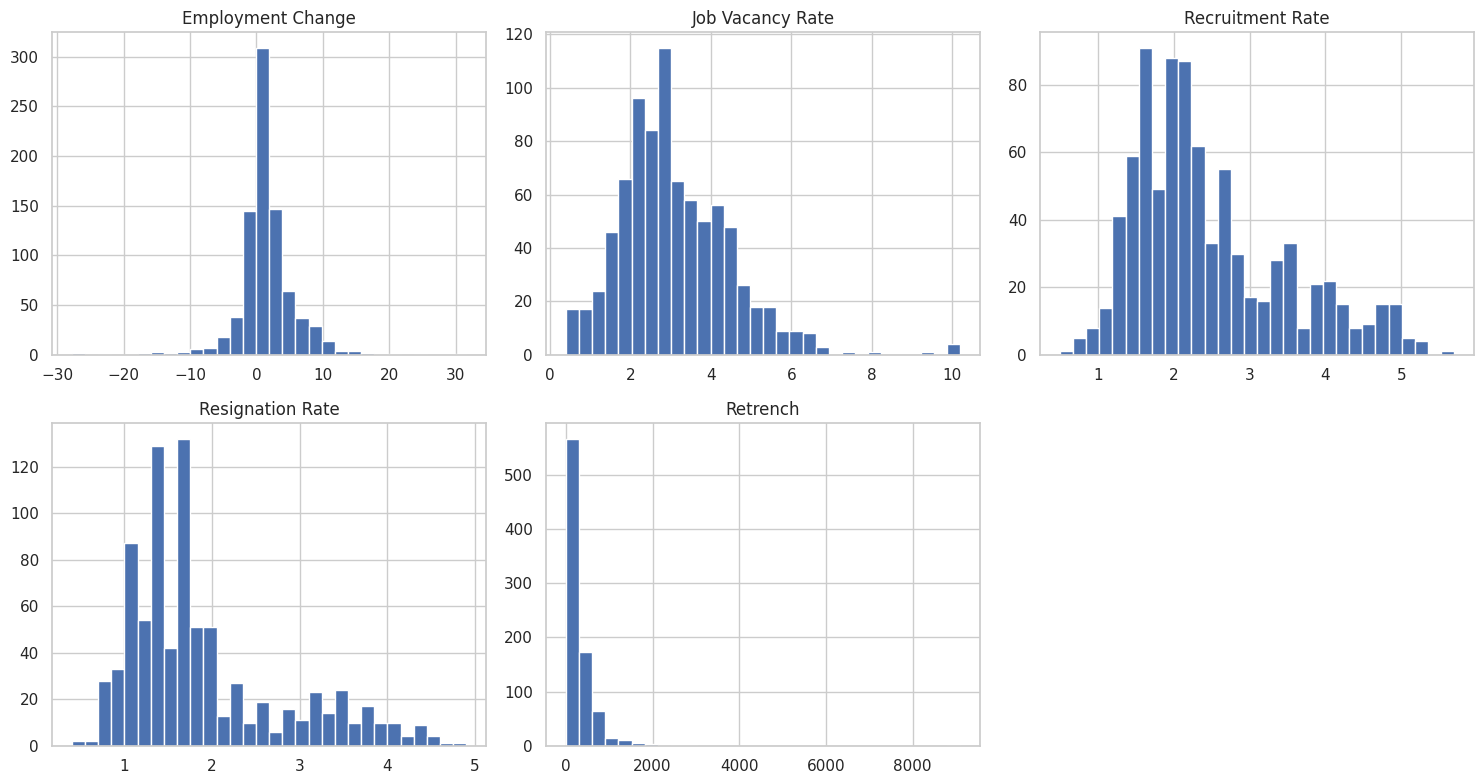

In [19]:
# Plot distributions of the five labour-market indicators

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, column in enumerate(indicators):
    axes[i].hist(df_master[column].dropna(), bins=30)
    axes[i].set_title(column.replace("_", " ").title())

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


In [20]:
# Calculate median indicator values across industries for each quarter
quarterly_median = (
    df_master
    .groupby("quarter")[indicators]
    .median()
    .reset_index()
)

quarterly_median.head()


,quarter,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
0,2009Q1,5.000000e-02,1.05,2.00,1.65,290.0
1,2009Q2,2.775558e-17,1.25,2.00,1.65,235.0
2,2009Q3,8.500000e-01,2.00,2.55,1.75,135.0
3,2009Q4,1.900000e+00,1.90,2.40,1.70,85.0
4,2010Q1,2.050000e+00,2.10,2.55,1.75,130.0


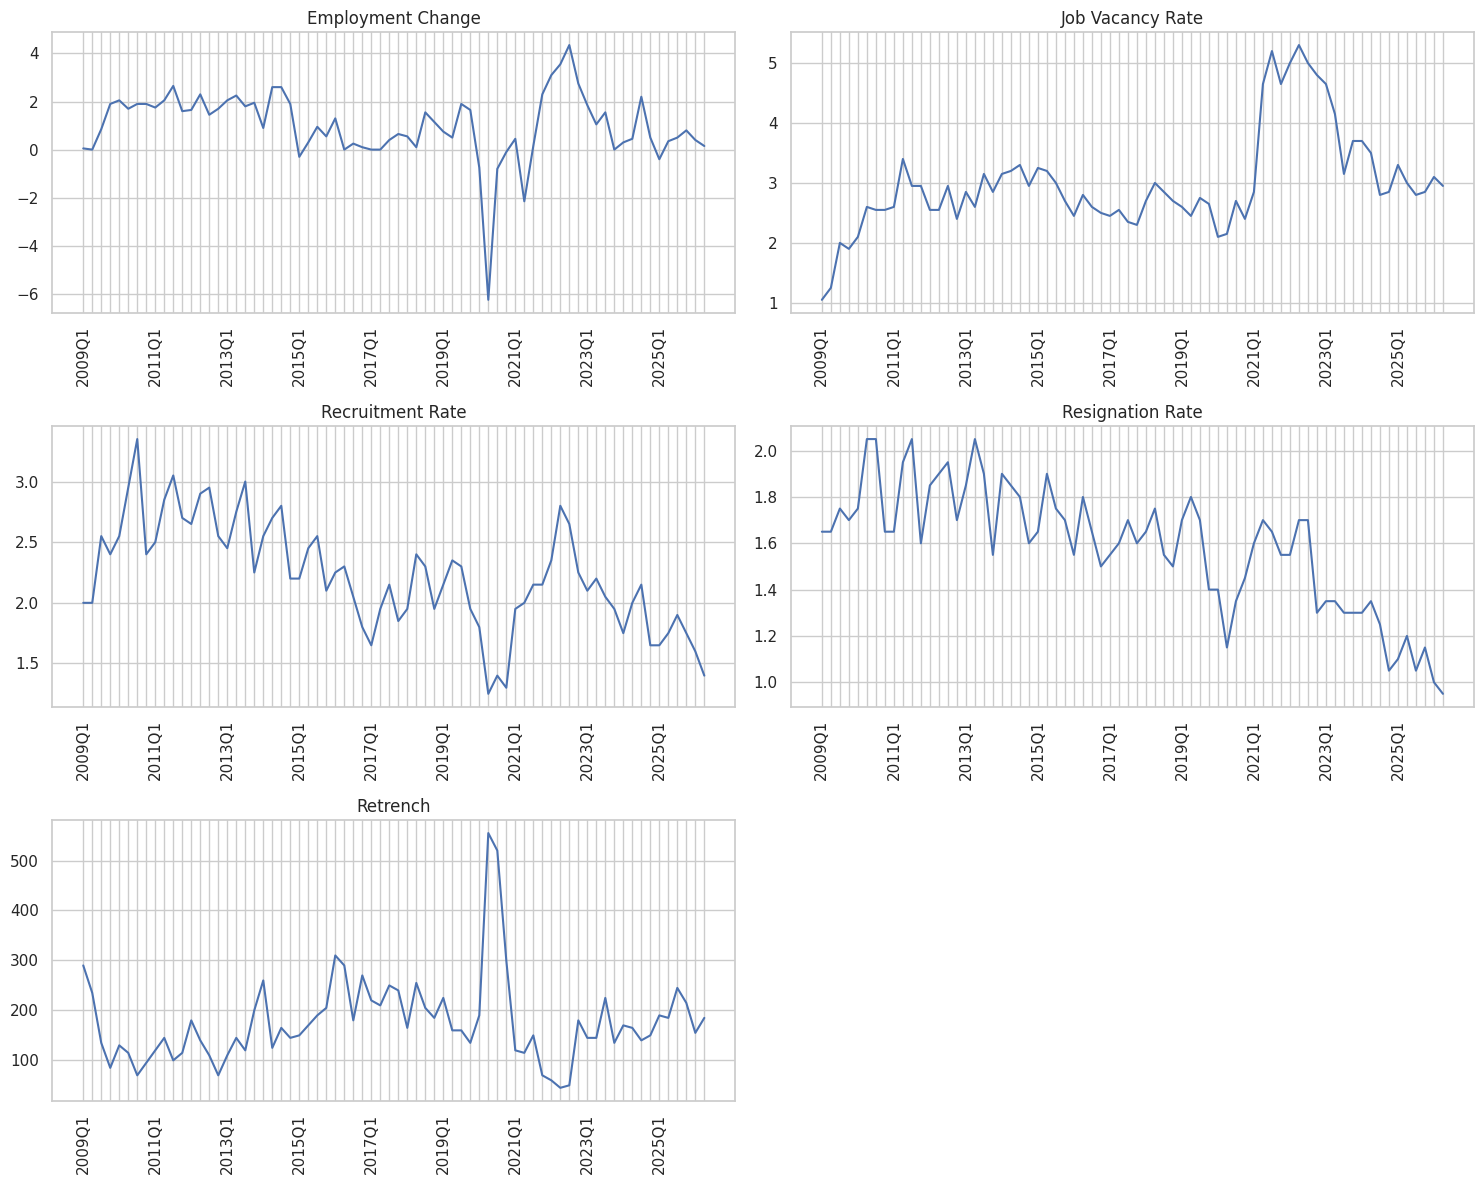

In [21]:
# Plot median quarterly trends for each labour-market indicator

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, column in enumerate(indicators):
    axes[i].plot(
        quarterly_median["quarter"].astype(str),
        quarterly_median[column]
    )

    axes[i].set_title(column.replace("_", " ").title())
    axes[i].tick_params(axis="x", rotation=90)

# Show fewer x-axis labels for readability
for ax in axes[:5]:
    for index, label in enumerate(ax.get_xticklabels()):
        label.set_visible(index % 8 == 0)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


In [22]:
# Calculate historical median indicator values by industry
industry_median = (
    df_master
    .groupby("industry")[indicators]
    .median()
    .round(2)
)

industry_median


,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
industry,,,,,
accommodation and food services,0.90,4.20,4.00,3.55,50.0
administrative and support services,1.90,3.40,4.40,3.40,80.0
"community, social and personal services",7.20,3.90,1.60,1.10,60.0
construction,3.65,1.30,2.30,1.70,205.0
financial and insurance services,1.40,2.95,1.90,1.20,370.0
information and communications,1.20,4.15,2.45,1.70,215.0
manufacturing,-0.50,2.00,1.70,1.50,865.0
others,0.00,2.45,1.70,1.30,0.0
professional services,1.80,2.60,2.30,1.60,335.0


In [23]:
# Calculate correlation matrix
correlation_matrix = (
    df_master[indicators]
    .corr()
    .round(2)
)

correlation_matrix


,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
employment_change,1.00,0.22,0.18,-0.04,-0.35
job_vacancy_rate,0.22,1.00,0.28,0.24,-0.24
recruitment_rate,0.18,0.28,1.00,0.92,-0.27
resignation_rate,-0.04,0.24,0.92,1.00,-0.19
retrench,-0.35,-0.24,-0.27,-0.19,1.00


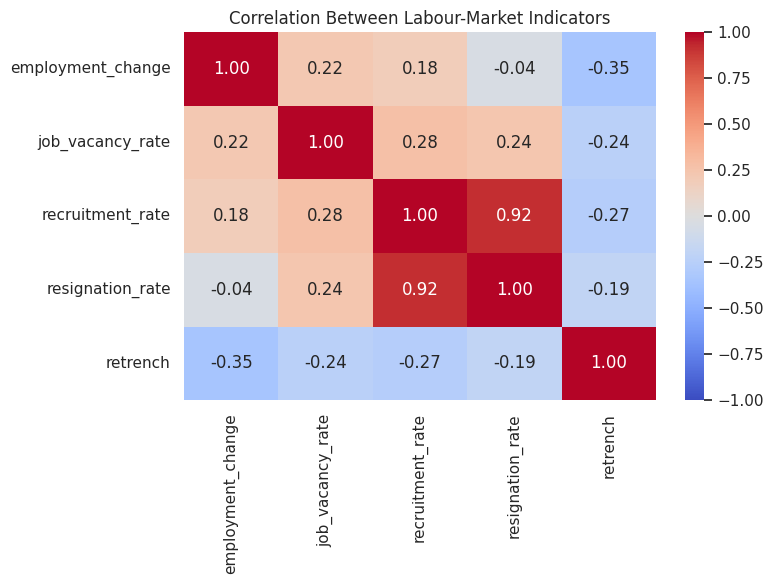

In [24]:
# Visualise correlations between labour-market indicators

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Labour-Market Indicators")
plt.tight_layout()
plt.show()


In [25]:
# Calculate variation in each indicator within industries over time

industry_variation = (
    df_master
    .groupby("industry")[indicators]
    .std()
    .round(2)
)

industry_variation


,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench
industry,,,,,
accommodation and food services,4.94,1.23,0.77,0.76,112.39
administrative and support services,2.47,0.91,0.89,0.75,100.59
"community, social and personal services",5.70,0.83,0.34,0.17,244.40
construction,8.63,1.08,0.65,0.31,178.89
financial and insurance services,1.45,1.11,0.47,0.31,172.65
information and communications,1.76,2.01,0.50,0.31,181.03
manufacturing,5.55,0.82,0.36,0.27,1094.13
others,0.32,0.86,0.48,0.43,22.30
professional services,1.94,1.08,0.47,0.27,179.66


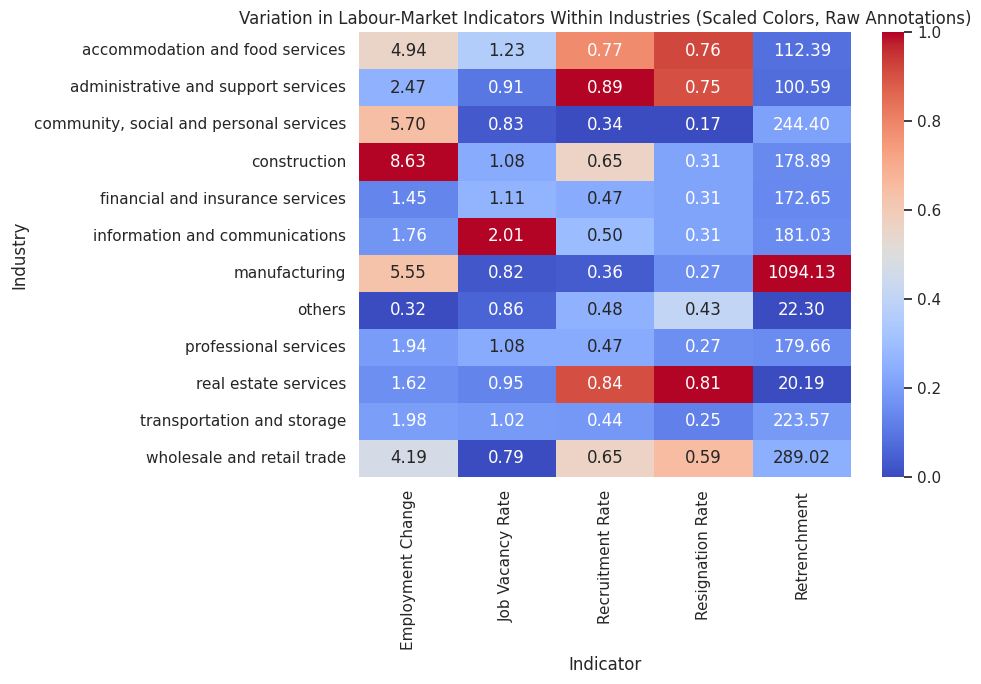

In [26]:
# Scale the variation columns (0 to 1) for a fair comparison in the heatmap
variation_scaled = (industry_variation - industry_variation.min()) / (industry_variation.max() - industry_variation.min())

# Rename indicators for clearer visualisation
display_names = {
    "employment_change": "Employment Change",
    "job_vacancy_rate": "Job Vacancy Rate",
    "recruitment_rate": "Recruitment Rate",
    "resignation_rate": "Resignation Rate",
    "retrench": "Retrenchment"
}

# Rename columns for display only
variation_scaled_display = variation_scaled.rename(columns=display_names)
industry_variation_display = industry_variation.rename(columns=display_names)

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    variation_scaled_display,
    annot=industry_variation_display,
    fmt=".2f",
    cmap="coolwarm",
    center=0.5
)

plt.title("Variation in Labour-Market Indicators Within Industries (Scaled Colors, Raw Annotations)")
plt.xlabel("Indicator")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()


## 3. Feature engineering


### Feature types and temporal design

| Variable group | Variables | Type | Role |
|---|---|---|---|
| Identifier | `industry` | Categorical | Separate industry histories and comparisons |
| Time index | `quarter` | Ordered quarterly period | Chronological ordering, lagging and holdout splits |
| Original MOM indicators | Employment change, vacancy, recruitment, resignation, retrenchments | Numerical | Historical measurements |
| Engineered indicators | Five 12-quarter rolling Z-scores and five quarter-on-quarter differences | Numerical | Clustering and supervised predictors |
| Historical K-Means state | Strong / Active, Cooling / Soft, Severe Disruption | Categorical, analyst-interpreted | Descriptive historical grouping, **not** the supervised target |
| Supervised target | `stress_next_q` | Binary | Next-quarter analyst-defined stress label |

The analysis uses repeated quarterly observations for each industry, not independent cross-sectional samples. Temporal order is preserved for rolling features, transitions and chronological model evaluation.


In [27]:
# Create a working copy for feature engineering

df_features = df_master.copy()

df_features = (
    df_features
    .sort_values(["industry", "quarter"])
    .reset_index(drop=True)
)


In [28]:
# Calculate quarter-on-quarter changes for each indicator - current quarter minus previous quarter value
for column in indicators:
    df_features[f"{column}_qoq_change"] = (
        df_features
        .groupby("industry")[column]
        .diff()
    )

df_features.head()


,quarter,industry,employment_change,job_vacancy_rate,recruitment_rate,resignation_rate,retrench,employment_change_qoq_change,job_vacancy_rate_qoq_change,recruitment_rate_qoq_change,resignation_rate_qoq_change,retrench_qoq_change
0,2009Q1,accommodation and food services,-2.7,1.0,2.9,3.7,40.0,NaN,NaN,NaN,NaN,NaN
1,2009Q2,accommodation and food services,-1.6,1.6,3.6,4.0,90.0,1.1,0.6,0.7,0.3,50.0
2,2009Q3,accommodation and food services,0.4,3.6,4.1,4.0,10.0,2.0,2.0,0.5,0.0,-80.0
3,2009Q4,accommodation and food services,6.1,3.2,4.5,3.7,60.0,5.7,-0.4,0.4,-0.3,50.0
4,2010Q1,accommodation and food services,2.8,3.9,4.1,4.2,60.0,-3.3,0.7,-0.4,0.5,0.0


In [29]:
# Create industry-relative features using the previous 12 quarters

for column in indicators:

    historical_mean = (
        df_features
        .groupby("industry")[column]
        .transform(
            lambda x: x.shift(1).rolling(
                window=12,
                min_periods=12
            ).mean()
        )
    )

    historical_std = (
        df_features
        .groupby("industry")[column]
        .transform(
            lambda x: x.shift(1).rolling(
                window=12,
                min_periods=12
            ).std()
        )
    )

    df_features[f"{column}_zscore"] = (
        (df_features[column] - historical_mean)
        / historical_std
    )


Historical Z-scores measure how unusual the current indicator value is relative to the same industry's preceding 12 quarters.

A Z-score close to zero indicates a value near the recent historical average; positive and negative scores indicate values above and below that average, respectively.

The reference window is shifted by one quarter, so the current observation does not contribute to its own historical benchmark. The first 12 quarters within each industry consequently have no complete rolling benchmark.

For indicator $X$, industry $i$ and quarter $t$:

$$Z_{i,t} = \frac{X_{i,t} - \mu_{i,t-12:t-1}}{\sigma_{i,t-12:t-1}}.$$

The mean and sample standard deviation use the **previous 12 quarters only**. Quarter-on-quarter change is $\Delta X_{i,t}=X_{i,t}-X_{i,t-1}$. Observations with undefined Z-scores, including those arising from a zero historical standard deviation, are excluded from complete-feature modelling.

In [30]:
# Define engineered feature groups

qoq_columns = [
    f"{column}_qoq_change"
    for column in indicators
]

zscore_columns = [
    f"{column}_zscore"
    for column in indicators
]

engineered_features = (
    qoq_columns
    + zscore_columns
)

print("QoQ features:", len(qoq_columns))
print("Z-score features:", len(zscore_columns))
print("Total engineered features:", len(engineered_features))


QoQ features: 5
Z-score features: 5
Total engineered features: 10


Missing values produced by feature engineering are expected at the beginning of each industry's history. Quarter-on-quarter changes require a preceding quarter, while rolling Z-scores require 12 earlier quarters. These missing values are retained rather than replaced with zeros, which would introduce artificial observations.

The two sets of engineered features serve different purposes in the subsequent analysis.

The **industry-relative z-scores** are used for PCA and clustering because the objective is to identify underlying labour-market patterns and states based on how current conditions compare with each industry's recent historical baseline.

For the supervised next-quarter stress model, both the **z-scores and QoQ changes** are used. This allows the model to consider both the industry's current position relative to its historical norm and its short-term movement from the previous quarter.


## 4. Principal component analysis (PCA)


In [31]:
# Select industry-relative z-score features for PCA

pca_features = zscore_columns.copy()

df_pca = df_features[
    ["quarter", "industry"] + pca_features
].dropna().copy()

print("PCA dataset shape:", df_pca.shape)
print("Number of industries:", df_pca["industry"].nunique())
print(
    "Period:",
    df_pca["quarter"].min(),
    "to",
    df_pca["quarter"].max()
)


PCA dataset shape: (696, 7)
Number of industries: 12
Period: 2012Q1 to 2026Q2


In [32]:
# Standardise PCA features

scaler = StandardScaler()

X_pca_scaled = scaler.fit_transform(
    df_pca[pca_features]
)

# Check the standardised values
pd.DataFrame(
    X_pca_scaled,
    columns=pca_features
).describe().round(2)


,employment_change_zscore,job_vacancy_rate_zscore,recruitment_rate_zscore,resignation_rate_zscore,retrench_zscore
count,696.00,696.00,696.00,696.00,696.00
mean,0.00,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-7.68,-3.44,-5.12,-4.66,-1.94
25%,-0.47,-0.69,-0.68,-0.64,-0.52
50%,0.05,-0.15,-0.06,-0.03,-0.23
75%,0.59,0.55,0.65,0.63,0.23
max,3.21,4.90,4.26,6.01,8.61


In [33]:
# Fit PCA using all five components initially

pca = PCA()

X_pca = pca.fit_transform(X_pca_scaled)

# Create explained variance table
explained_variance = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Explained Variance (%)":
        pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)":
        np.cumsum(pca.explained_variance_ratio_) * 100
})

explained_variance.round(2)


,Principal Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,47.68,47.68
1,PC2,19.24,66.92
2,PC3,13.93,80.85
3,PC4,13.13,93.98
4,PC5,6.02,100.00


In [34]:
# Examine how strongly each original indicator contributes to each component

pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=pca_features,
    columns=[
        f"PC{i+1}"
        for i in range(len(pca_features))
    ]
)

pca_loadings.round(2)


,PC1,PC2,PC3,PC4,PC5
employment_change_zscore,0.44,-0.45,0.23,0.64,-0.37
job_vacancy_rate_zscore,0.41,0.33,0.79,-0.30,0.05
recruitment_rate_zscore,0.55,0.10,-0.28,0.23,0.74
resignation_rate_zscore,0.46,0.50,-0.46,-0.12,-0.56
retrench_zscore,-0.35,0.65,0.15,0.66,0.03


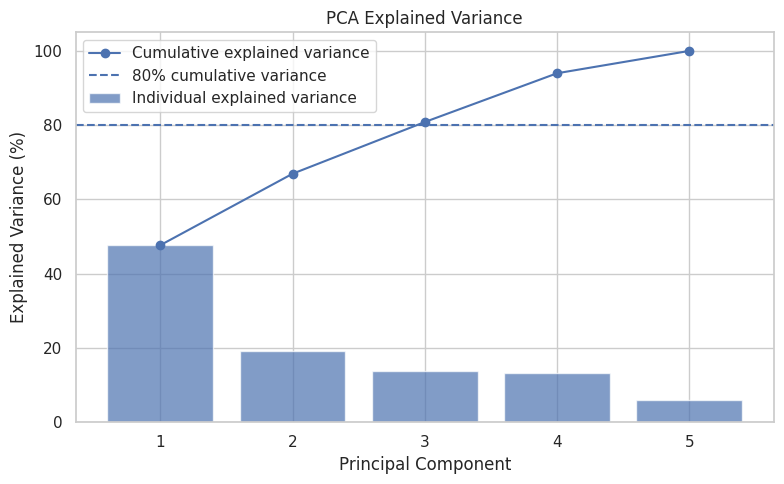

In [35]:
# Plot explained and cumulative variance

components = np.arange(1, len(pca.explained_variance_ratio_) + 1)

plt.figure(figsize=(8, 5))

plt.bar(
    components,
    pca.explained_variance_ratio_ * 100,
    alpha=0.7,
    label="Individual explained variance"
)

plt.plot(
    components,
    np.cumsum(pca.explained_variance_ratio_) * 100,
    marker="o",
    label="Cumulative explained variance"
)

plt.axhline(
    y=80,
    linestyle="--",
    label="80% cumulative variance"
)

plt.xticks(components)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()


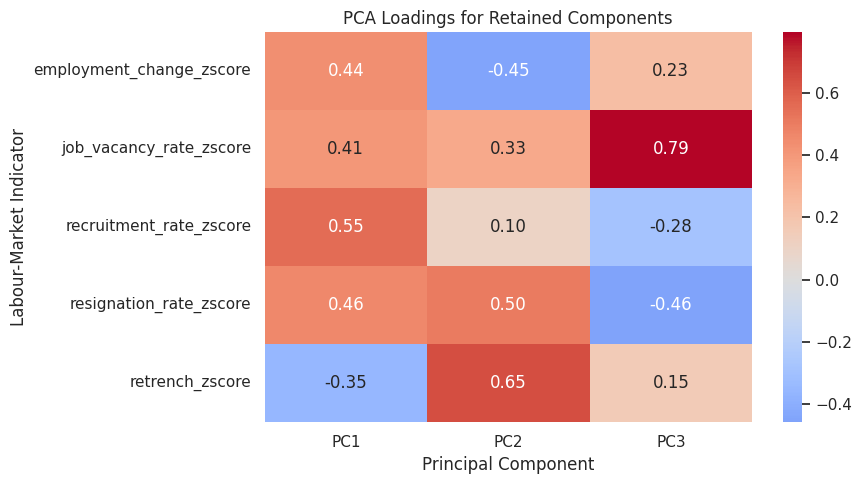

In [36]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    pca_loadings[["PC1", "PC2", "PC3"]],
    annot=True,
    fmt=".2f",
    center=0,
    cmap="coolwarm"
)

plt.title("PCA Loadings for Retained Components")
plt.xlabel("Principal Component")
plt.ylabel("Labour-Market Indicator")

plt.tight_layout()
plt.show()


## 5. Historical labour market states: K-Means

This stage identifies recurring combinations of industry-relative labour market conditions. The resulting states are descriptive; chronological transition frequencies are examined separately.

K-Means does not model sequential dependence. Nevertheless, each historical Z-score incorporates information from the same industry's preceding 12 quarters, providing context for the current observation without treating K-Means as a temporal forecasting algorithm.

K-Means minimises within-cluster squared Euclidean distance and therefore favours relatively compact groupings. Alternative Gaussian-mixture and density-based methods are compared below to assess sensitivity to that assumption. The three-state solution is retained as an interpretable analytical framework rather than a uniquely optimal classification. PCA and clustering are fitted to the full historical sample for descriptive analysis; cluster labels are not supplied to the supervised classifier.

In [37]:
# Retain the first three principal components

df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]
df_pca["PC3"] = X_pca[:, 2]

cluster_features = ["PC1", "PC2", "PC3"]

df_pca = df_pca.reset_index(drop=True)

df_pca[
    ["quarter", "industry"] + cluster_features
].head()


,quarter,industry,PC1,PC2,PC3
0,2012Q1,accommodation and food services,0.178337,2.399501,-0.828485
1,2012Q2,accommodation and food services,0.940878,0.867924,-1.748208
2,2012Q3,accommodation and food services,1.318305,0.736534,1.812015
3,2012Q4,accommodation and food services,1.069024,-1.435098,0.779283
4,2013Q1,accommodation and food services,-0.177584,0.322661,0.048447


In [38]:
# Test different numbers of clusters

inertia_values = []
silhouette_values = []

k_values = range(2, 7)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        df_pca[cluster_features]
    )

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(
            df_pca[cluster_features],
            cluster_labels
        )
    )

# Display results
cluster_evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

cluster_evaluation.round(3)


,K,Inertia,Silhouette Score
0,2,1792.114,0.337
1,3,1419.227,0.345
2,4,1197.904,0.254
3,5,1045.991,0.258
4,6,918.870,0.267


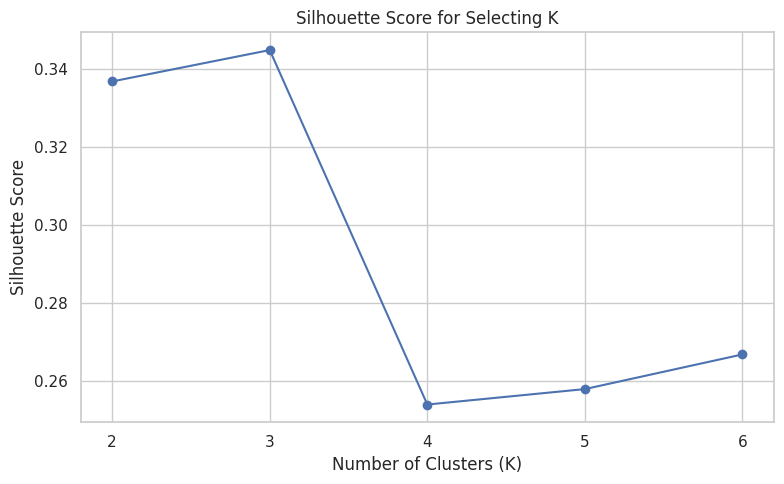

In [39]:
# Plot silhouette scores

plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Silhouette Score"],
    marker="o"
)


plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Selecting K")
plt.xticks(cluster_evaluation["K"])
plt.tight_layout()
plt.show()


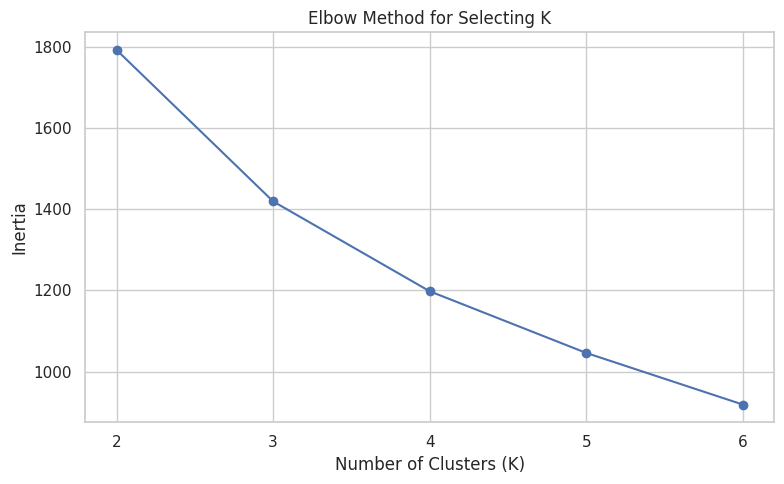

In [40]:
# Plot elbow method

plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["K"],
    cluster_evaluation["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Selecting K")
plt.xticks(cluster_evaluation["K"])
plt.tight_layout()
plt.show()


In [41]:
# Fit final K-Means model using K = 3

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df_pca["cluster"] = kmeans_final.fit_predict(
    df_pca[cluster_features]
)

# Examine cluster sizes
df_pca["cluster"].value_counts().sort_index()


,count
cluster,
0,42
1,268
2,386


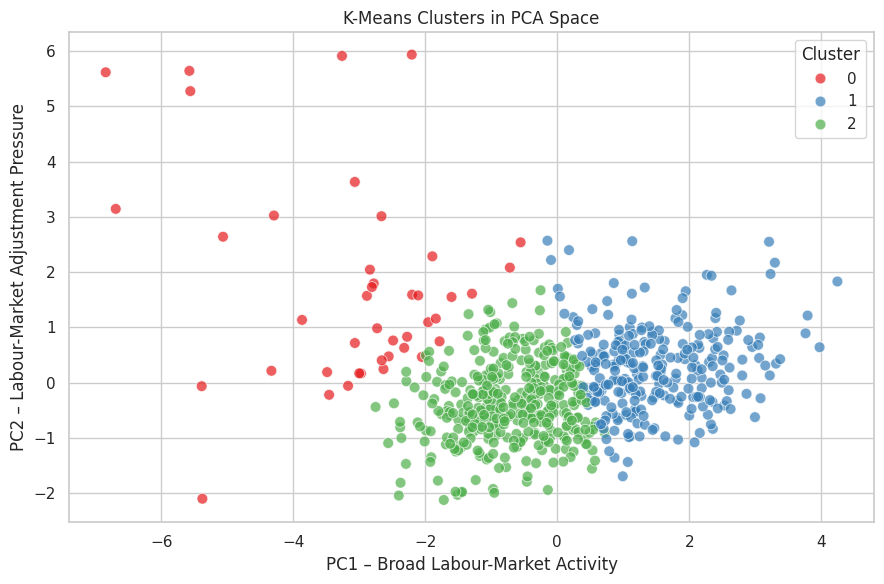

In [42]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df_pca,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1",
    s=60,
    alpha=0.7
)

plt.xlabel("PC1 – Broad Labour-Market Activity")
plt.ylabel("PC2 – Labour-Market Adjustment Pressure")
plt.title("K-Means Clusters in PCA Space")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()


In [43]:
# Profile clusters using the original industry-relative indicators

cluster_profile = (
    df_pca
    .groupby("cluster")[pca_features]
    .mean()
    .round(2)
)

cluster_profile


,employment_change_zscore,job_vacancy_rate_zscore,recruitment_rate_zscore,resignation_rate_zscore,retrench_zscore
cluster,,,,,
0,-2.86,-0.79,-2.14,-1.50,5.05
1,0.55,1.20,0.69,0.49,-0.31
2,-0.37,-0.68,-0.93,-1.01,0.32


In [44]:
# Assign descriptive labels to the three clusters

state_labels = {
    0: "Severe Disruption",
    1: "Strong / Active",
    2: "Cooling / Soft"
}

df_pca["state"] = df_pca["cluster"].map(state_labels)

# Sort observations chronologically within each industry
df_pca = (
    df_pca
    .sort_values(["industry", "quarter"])
    .reset_index(drop=True)
)

df_pca[
    ["quarter", "industry", "cluster", "state"]
].head(15)


,quarter,industry,cluster,state
0,2012Q1,accommodation and food services,1,Strong / Active
1,2012Q2,accommodation and food services,1,Strong / Active
2,2012Q3,accommodation and food services,1,Strong / Active
3,2012Q4,accommodation and food services,1,Strong / Active
4,2013Q1,accommodation and food services,2,Cooling / Soft
5,2013Q2,accommodation and food services,1,Strong / Active
6,2013Q3,accommodation and food services,2,Cooling / Soft
7,2013Q4,accommodation and food services,1,Strong / Active
8,2014Q1,accommodation and food services,2,Cooling / Soft
9,2014Q2,accommodation and food services,1,Strong / Active


### Robustness check: alternative clustering assumptions

Gaussian Mixture Models (GMM) allow more flexible covariance structures and probabilistic component membership. HDBSCAN examines density-connected groupings and can classify sparsely located observations as noise. These alternatives provide a sensitivity check on the K-Means partition.

Silhouette scores are most comparable across methods when they describe the same observations and number of groups. BIC is compared among the GMM candidates. Cluster label numbers are arbitrary across algorithms; agreement is evaluated using the Adjusted Rand Index (ARI), not by matching label numbers.

In [45]:
# Compare alternative clustering assumptions using the same PCA feature space.
X_states = df_pca[cluster_features].to_numpy()
comparison_rows = [{
    "Method": "K-Means (3)", "Clusters": 3, "Noise (%)": 0.0,
    "Silhouette (assigned)": silhouette_score(X_states, df_pca["cluster"]),
    "ARI vs K-Means": 1.0, "BIC (GMM only)": np.nan
}]
gmm_labels_by_k = {}
for k in [2, 3, 4, 5]:
    gmm = GaussianMixture(n_components=k, covariance_type="full",
                          random_state=42, n_init=5, reg_covar=1e-5)
    labels = gmm.fit_predict(X_states)
    gmm_labels_by_k[k] = labels
    comparison_rows.append({
        "Method": f"GMM full ({k})", "Clusters": len(np.unique(labels)),
        "Noise (%)": 0.0,
        "Silhouette (assigned)": silhouette_score(X_states, labels),
        "ARI vs K-Means": adjusted_rand_score(df_pca["cluster"], labels),
        "BIC (GMM only)": gmm.bic(X_states)
    })

# sklearn >=1.3 supplies HDBSCAN; older environments may skip this optional check.
if HDBSCAN is not None:
    for min_size, min_samples in [(10, 5), (20, 5), (20, 10)]:
        labels = HDBSCAN(min_cluster_size=min_size,
                         min_samples=min_samples).fit_predict(X_states)
        assigned = labels != -1
        n_groups = len(set(labels[assigned]))
        score = (silhouette_score(X_states[assigned], labels[assigned])
                 if n_groups >= 2 and assigned.sum() > n_groups else np.nan)
        comparison_rows.append({
            "Method": f"HDBSCAN (size={min_size}, samples={min_samples})",
            "Clusters": n_groups, "Noise (%)": 100 * (~assigned).mean(),
            "Silhouette (assigned)": score,
            "ARI vs K-Means": (adjusted_rand_score(df_pca.loc[assigned, "cluster"], labels[assigned])
                                if assigned.any() else np.nan),
            "BIC (GMM only)": np.nan
        })
else:
    print("Optional HDBSCAN check skipped: sklearn.cluster.HDBSCAN unavailable.")

cluster_method_comparison = pd.DataFrame(comparison_rows)
display(cluster_method_comparison.round(3))
print("GMM BIC favours:", cluster_method_comparison.dropna(subset=["BIC (GMM only)"])
      .sort_values("BIC (GMM only)").iloc[0]["Method"])

# Profile the three-component GMM in ORIGINAL Z-score units.
df_gmm_profile = df_pca.copy()
df_gmm_profile["gmm_cluster"] = gmm_labels_by_k[3]
display(df_gmm_profile.groupby("gmm_cluster")[pca_features].mean().round(2))


,Method,Clusters,Noise (%),Silhouette (assigned),ARI vs K-Means,BIC (GMM only)
0,K-Means (3),3,0.000,0.345,1.000,NaN
1,GMM full (2),2,0.000,0.403,0.154,5984.886
2,GMM full (3),3,0.000,0.327,0.698,6005.244
3,GMM full (4),4,0.000,0.205,0.245,6058.433
4,GMM full (5),5,0.000,0.218,0.457,6070.168
5,"HDBSCAN (size=10, samples=5)",2,45.833,0.382,0.087,NaN
6,"HDBSCAN (size=20, samples=5)",2,76.580,0.503,0.572,NaN
7,"HDBSCAN (size=20, samples=10)",2,84.626,0.454,0.368,NaN


GMM BIC favours: GMM full (2)


,employment_change_zscore,job_vacancy_rate_zscore,recruitment_rate_zscore,resignation_rate_zscore,retrench_zscore
gmm_cluster,,,,,
0,0.67,1.09,0.62,0.33,-0.39
1,-0.51,-0.82,-0.94,-0.96,0.41
2,-2.17,1.01,-1.50,-0.90,4.24


**Interpretation of the clustering comparison.** The three-component GMM shows how closely an alternative three-group partition agrees with K-Means. Lower BIC for a two-component GMM supports the possibility of a simpler partition under the GMM assumptions. HDBSCAN silhouette scores exclude noise observations and must be interpreted alongside the proportion left unassigned.

These comparisons test sensitivity to modelling assumptions; they do not establish independently verified labour market categories. K-Means was retained because its states were interpretable and it assigned every observation, rather than because it outperformed all alternative methods on every statistic.

In [46]:
# Identify each industry's following quarter and ensure transitions are truly consecutive.
df_pca["next_state"] = df_pca.groupby("industry")["state"].shift(-1)
df_pca["next_quarter"] = df_pca.groupby("industry")["quarter"].shift(-1)
df_pca["is_consecutive_quarter"] = (df_pca["next_quarter"] == df_pca["quarter"] + 1)
valid_transitions = df_pca.loc[df_pca["is_consecutive_quarter"]].copy()
print(f"Valid consecutive-quarter transitions: {len(valid_transitions)}")
display(valid_transitions[["quarter", "industry", "state", "next_state", "next_quarter"]].head(15))


Valid consecutive-quarter transitions: 684


,quarter,industry,state,next_state,next_quarter
0,2012Q1,accommodation and food services,Strong / Active,Strong / Active,2012Q2
1,2012Q2,accommodation and food services,Strong / Active,Strong / Active,2012Q3
2,2012Q3,accommodation and food services,Strong / Active,Strong / Active,2012Q4
3,2012Q4,accommodation and food services,Strong / Active,Cooling / Soft,2013Q1
4,2013Q1,accommodation and food services,Cooling / Soft,Strong / Active,2013Q2
5,2013Q2,accommodation and food services,Strong / Active,Cooling / Soft,2013Q3
6,2013Q3,accommodation and food services,Cooling / Soft,Strong / Active,2013Q4
7,2013Q4,accommodation and food services,Strong / Active,Cooling / Soft,2014Q1
8,2014Q1,accommodation and food services,Cooling / Soft,Strong / Active,2014Q2
9,2014Q2,accommodation and food services,Strong / Active,Strong / Active,2014Q3


In [47]:
# Create transition count matrix

state_order = [
    "Strong / Active",
    "Cooling / Soft",
    "Severe Disruption"
]

transition_counts = pd.crosstab(
    valid_transitions["state"],
    valid_transitions["next_state"]
).reindex(
    index=state_order,
    columns=state_order,
    fill_value=0
)

transition_counts


next_state,Strong / Active,Cooling / Soft,Severe Disruption
state,,,
Strong / Active,180,84,4
Cooling / Soft,71,277,27
Severe Disruption,7,23,11


In [48]:
# Convert transition counts into row percentages

transition_percent = (
    transition_counts
    .div(transition_counts.sum(axis=1), axis=0)
    * 100
).round(1)

transition_percent

print("Historical transition rates describe observed movements, NOT next-quarter predictive accuracy.")


Historical transition rates describe observed movements, NOT next-quarter predictive accuracy.


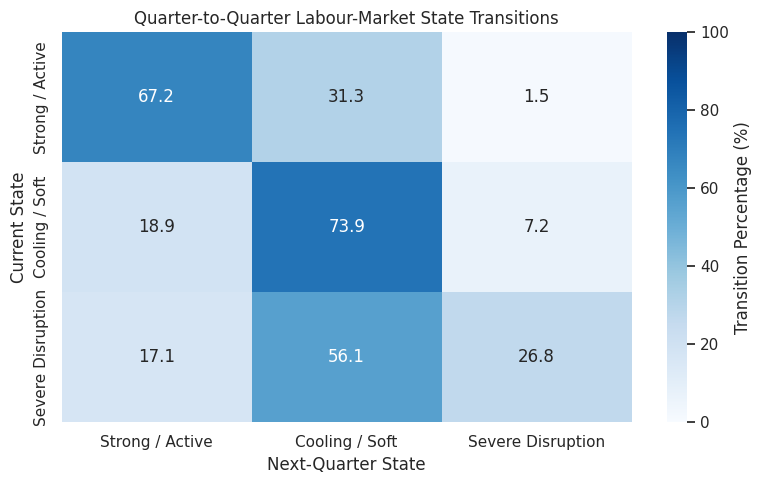

In [49]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    transition_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Transition Percentage (%)"}
)

plt.title("Quarter-to-Quarter Labour-Market State Transitions")
plt.xlabel("Next-Quarter State")
plt.ylabel("Current State")
plt.tight_layout()
plt.show()


In [50]:
# Sensitivity analysis excluding transitions into 2020Q1 and 2020Q2

transition_sensitivity = valid_transitions[
    ~valid_transitions["next_quarter"].isin([
        pd.Period("2020Q1", freq="Q"),
        pd.Period("2020Q2", freq="Q")
    ])
].copy()

transition_percent_excl_covid = (
    pd.crosstab(
        transition_sensitivity["state"],
        transition_sensitivity["next_state"]
    )
    .reindex(
        index=state_order,
        columns=state_order,
        fill_value=0
    )
)

transition_percent_excl_covid = (
    transition_percent_excl_covid
    .div(transition_percent_excl_covid.sum(axis=1), axis=0)
    * 100
).round(1)

transition_percent_excl_covid


next_state,Strong / Active,Cooling / Soft,Severe Disruption
state,,,
Strong / Active,67.2,31.3,1.5
Cooling / Soft,20.1,75.7,4.2
Severe Disruption,18.4,60.5,21.1


In [51]:
# Compare transition percentages: Full sample vs COVID-excluded

transition_comparison = pd.DataFrame({
    "Full Sample (%)": transition_percent["Severe Disruption"],
    "Excluding COVID Onset (%)": transition_percent_excl_covid["Severe Disruption"]
})

transition_comparison = transition_comparison.reindex(state_order)

transition_comparison.round(1)


,Full Sample (%),Excluding COVID Onset (%)
state,,
Strong / Active,1.5,1.5
Cooling / Soft,7.2,4.2
Severe Disruption,26.8,21.1


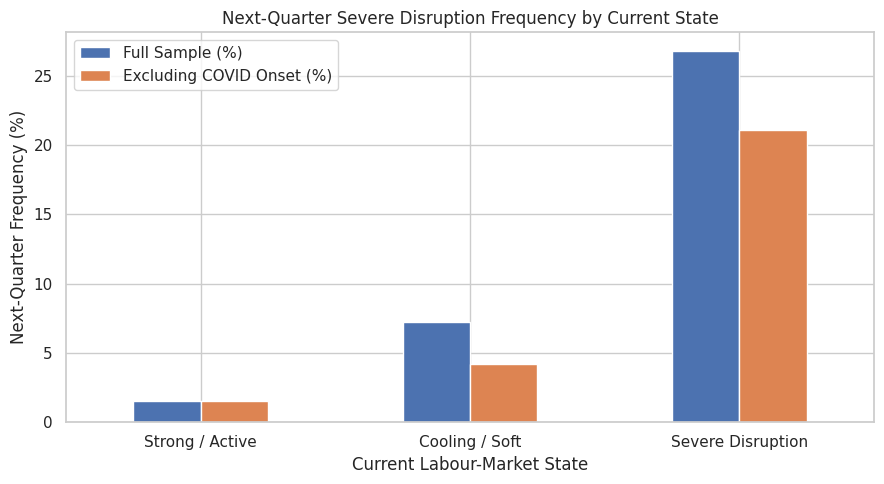

In [52]:
transition_comparison.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Next-Quarter Severe Disruption Frequency by Current State")
plt.xlabel("Current Labour-Market State")
plt.ylabel("Next-Quarter Frequency (%)")
plt.legend(title="")
plt.tight_layout()
plt.show()


### Historical transitions and temporal limitations

Each industry-quarter is assigned a K-Means state using current indicators expressed relative to the preceding 12 quarters. After clustering, states are ordered chronologically within industries, and transition frequencies are calculated only for observations separated by exactly one quarter. Rows of the resulting transition matrix sum to approximately 100%.

These rates describe observed persistence, deterioration and recovery between historical states. They are not forecasts and provide no evidence that K-Means improves the separate supervised stress classifier. The transition observations are serially dependent, and the Severe Disruption state contains relatively few observations, so the rates should be interpreted with caution.

## 6. Define industry-level labour market stress


In [53]:
# Create adverse-condition flags

df_features["weak_employment"] = (
    df_features["employment_change_zscore"] <= -1
).astype(int)

df_features["low_vacancies"] = (
    df_features["job_vacancy_rate_zscore"] <= -1
).astype(int)

df_features["low_recruitment"] = (
    df_features["recruitment_rate_zscore"] <= -1
).astype(int)

df_features["high_retrenchment"] = (
    df_features["retrench_zscore"] >= 1
).astype(int
)

# Number of adverse conditions in each industry-quarter
stress_flags = [
    "weak_employment",
    "low_vacancies",
    "low_recruitment",
    "high_retrenchment"
]

df_features["adverse_count"] = (
    df_features[stress_flags].sum(axis=1)
)

# Stressed = at least 2 adverse conditions
df_features["stress"] = (
    df_features["adverse_count"] >= 2
).astype(int)


In [54]:
# Check distribution of the stress classification

valid_stress = df_features[
    df_features[zscore_columns].notna().all(axis=1)
]["stress"]

print("Counts:")
print(valid_stress.value_counts())

print("\nPercentages:")
print(
    valid_stress.value_counts(normalize=True)
    .mul(100)
    .round(1)
)


Counts:
stress
0    495
1    201
Name: count, dtype: int64

Percentages:
stress
0    71.1
1    28.9
Name: proportion, dtype: float64


### Sensitivity and historical checks
The stress definition is an analyst-defined screening rule, not an official MOM classification.


,z_cutoff,stressed_observations,stress_rate_pct
0,0.5,347,49.9
1,1.0,201,28.9
2,1.5,86,12.4


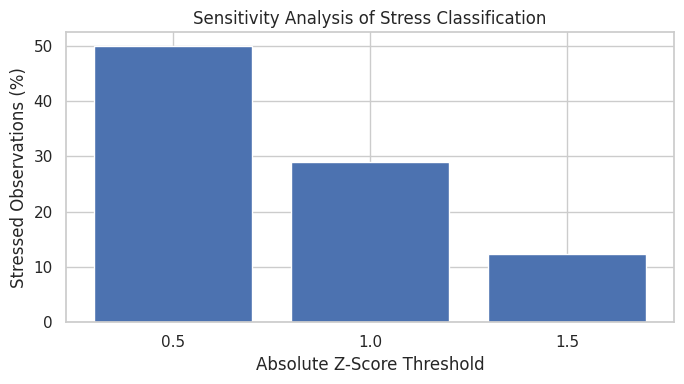

In [55]:
# Sensitivity Analysis: Testing Different Z-Score Thresholds

# Keep only observations with complete z-score data
valid_history = df_features.loc[
    df_features[zscore_columns].notna().all(axis=1)
].copy()

results = []

# Test three different z-score thresholds
for cutoff in [0.5, 1.0, 1.5]:

    # Identify adverse labour market conditions
    adverse_flags = pd.DataFrame({
        "employment": valid_history["employment_change_zscore"] <= -cutoff,
        "vacancies": valid_history["job_vacancy_rate_zscore"] <= -cutoff,
        "recruitment": valid_history["recruitment_rate_zscore"] <= -cutoff,
        "retrenchment": valid_history["retrench_zscore"] >= cutoff
    })

    # Count adverse indicators and classify stress
    stress = (adverse_flags.sum(axis=1) >= 2).astype(int)

    # Store results
    results.append({
        "z_cutoff": cutoff,
        "stressed_observations": int(stress.sum()),
        "stress_rate_pct": round(stress.mean() * 100, 1)
    })

# Display results
sensitivity_results = pd.DataFrame(results)
display(sensitivity_results)

# Visualise results
plt.figure(figsize=(7, 4))

plt.bar(
    sensitivity_results["z_cutoff"].astype(str),
    sensitivity_results["stress_rate_pct"]
)

plt.xlabel("Absolute Z-Score Threshold")
plt.ylabel("Stressed Observations (%)")
plt.title("Sensitivity Analysis of Stress Classification")

plt.tight_layout()
plt.show()


,quarter,industry_count,stressed_industries,stress_share_pct
38,2021Q3,12,0,0.000000
39,2021Q4,12,0,0.000000
40,2022Q1,12,0,0.000000
41,2022Q2,12,0,0.000000
42,2022Q3,12,0,0.000000
43,2022Q4,12,0,0.000000
44,2023Q1,12,1,8.333333
45,2023Q2,12,1,8.333333
46,2023Q3,12,1,8.333333
47,2023Q4,12,4,33.333333


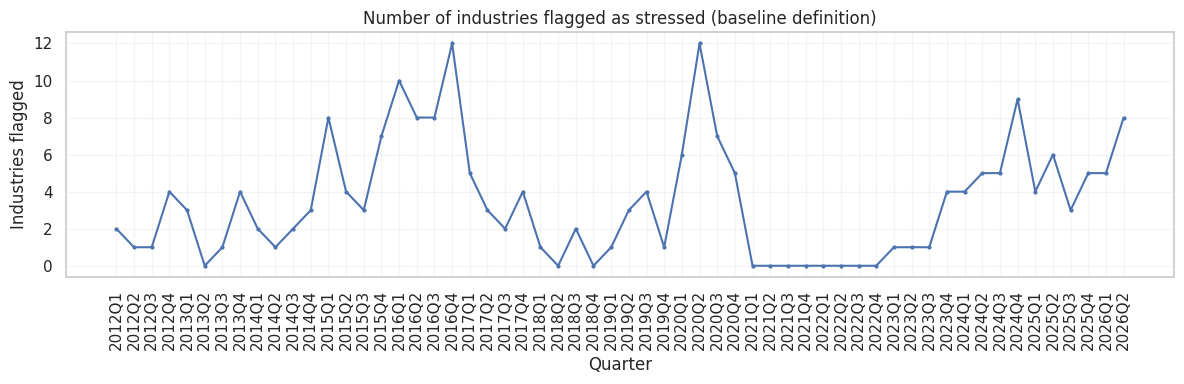

In [56]:
# Historical stress patterns under the baseline definition
# Only observations with complete 12-quarter histories are eligible.

historical_summary = (
    valid_history.groupby('quarter', as_index=False)
    .agg(industry_count=('industry', 'nunique'),
         stressed_industries=('stress', 'sum'))
)
historical_summary['stress_share_pct'] = (
    100 * historical_summary['stressed_industries'] / historical_summary['industry_count']
)
display(historical_summary.tail(20))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(historical_summary['quarter'].astype(str),
        historical_summary['stressed_industries'], marker='o', markersize=2)
ax.set_title('Number of industries flagged as stressed (baseline definition)')
ax.set_ylabel('Industries flagged')
ax.set_xlabel('Quarter')
ax.tick_params(axis='x', rotation=90)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [57]:
# Select six illustrative quarters for qualitative comparison
checkpoints = [
    '2019Q4', '2020Q2', '2021Q2',
    '2023Q4', '2024Q4', '2025Q4'
]

historical_checkpoints = historical_summary[
    historical_summary['quarter'].astype(str).isin(checkpoints)
].copy()

display(historical_checkpoints)


,quarter,industry_count,stressed_industries,stress_share_pct
31,2019Q4,12,1,8.333333
33,2020Q2,12,12,100.000000
37,2021Q2,12,0,0.000000
47,2023Q4,12,4,33.333333
51,2024Q4,12,9,75.000000
55,2025Q4,12,5,41.666667


## 7. Next-quarter supervised learning


In [58]:
# Sort observations chronologically within each industry
df_features = df_features.sort_values(
    ["industry", "quarter"]
).copy()

# Create next-quarter stress target
df_features["stress_next_q"] = (
    df_features.groupby("industry")["stress"].shift(-1)
)

# Check the result
display(
    df_features[
        ["industry", "quarter", "stress", "stress_next_q"]
    ].head(15)
)


,industry,quarter,stress,stress_next_q
0,accommodation and food services,2009Q1,0,0.0
1,accommodation and food services,2009Q2,0,0.0
2,accommodation and food services,2009Q3,0,0.0
3,accommodation and food services,2009Q4,0,0.0
4,accommodation and food services,2010Q1,0,0.0
5,accommodation and food services,2010Q2,0,0.0
6,accommodation and food services,2010Q3,0,0.0
7,accommodation and food services,2010Q4,0,0.0
8,accommodation and food services,2011Q1,0,0.0
9,accommodation and food services,2011Q2,0,0.0


In [59]:
# Define predictors

model_features = zscore_columns + qoq_columns

# Remove rows with missing predictors or target
model_df = df_features.dropna(
    subset=model_features + ["stress_next_q"]
).copy()

# Convert target to integer
model_df["stress_next_q"] = (
    model_df["stress_next_q"].astype(int)
)

# Ensure quarters are quarterly periods
model_df["quarter"] = pd.PeriodIndex(
    model_df["quarter"].astype(str),
    freq="Q"
)

model_df = model_df.sort_values(
    ["quarter", "industry"]
).reset_index(drop=True)

print("Total observations:", len(model_df))
print("Number of industries:", model_df["industry"].nunique())
print("Period:", model_df["quarter"].min(),
      "to", model_df["quarter"].max())

print("\nNext-quarter stress distribution (%):")
print(
    model_df["stress_next_q"]
    .value_counts(normalize=True)
    .mul(100)
    .round(1)
)


Total observations: 684
Number of industries: 12
Period: 2012Q1 to 2026Q1

Next-quarter stress distribution (%):
stress_next_q
0    70.9
1    29.1
Name: proportion, dtype: float64


In [60]:
# Identify the quarter being predicted

model_df["target_quarter"] = (
    model_df["quarter"] + 1
)

# Chronological split based on target quarter

train_df = model_df[
    model_df["target_quarter"] <= pd.Period("2022Q4", freq="Q")
].copy()

test_df = model_df[
    (model_df["target_quarter"] >= pd.Period("2023Q1", freq="Q")) &
    (model_df["target_quarter"] <= pd.Period("2026Q2", freq="Q"))
].copy()

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining feature quarters:",
      train_df["quarter"].min(),
      "to", train_df["quarter"].max())

print("Testing feature quarters:",
      test_df["quarter"].min(),
      "to", test_df["quarter"].max())

print("\nTraining target distribution (%):")
print(train_df["stress_next_q"].value_counts(normalize=True).mul(100).round(1))

print("\nTesting target distribution (%):")
print(test_df["stress_next_q"].value_counts(normalize=True).mul(100).round(1))


Training observations: 516
Testing observations: 168

Training feature quarters: 2012Q1 to 2022Q3
Testing feature quarters: 2022Q4 to 2026Q1

Training target distribution (%):
stress_next_q
0    73.3
1    26.7
Name: proportion, dtype: float64

Testing target distribution (%):
stress_next_q
0    63.7
1    36.3
Name: proportion, dtype: float64


### Model selection: expanding-window validation

Candidate models are compared using the same expanding-window folds within the earlier training period. The later chronological holdout is reserved for final evaluation.

Each of the four classifier families is evaluated with and without class balancing. Logistic Regression, Support Vector Machine and Random Forest use model-level class weighting where applicable; balanced Gradient Boosting uses sample weights derived exclusively from the corresponding training fold. The persistence baseline is assessed separately without class weighting. Precision, recall and F1 are reported because balancing may improve sensitivity to stress at the cost of additional false alerts.

In [61]:
# Paired balanced/unbalanced comparisons for all supervised model families.
models = {
    "Logistic Regression (unbalanced)": LogisticRegression(max_iter=1000, random_state=42),
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "SVM (unbalanced)": SVC(probability=True, random_state=42),
    "SVM (balanced)": SVC(class_weight="balanced", probability=True, random_state=42),
    "Random Forest (unbalanced)": RandomForestClassifier(n_estimators=200, random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
    "Gradient Boosting (unbalanced)": GradientBoostingClassifier(random_state=42),
    "Gradient Boosting (balanced)": GradientBoostingClassifier(random_state=42),
}

def build_estimator(name):
    estimator = clone(models[name])
    if name.startswith(("Logistic Regression", "SVM")):
        return make_pipeline(StandardScaler(), estimator)
    return estimator

def balanced_sample_weights(y):
    # Per-training-fold inverse-frequency weights; no validation/test labels used.
    return compute_sample_weight(class_weight="balanced", y=y)

def fit_candidate(name, X, y):
    estimator = build_estimator(name)
    if name == "Gradient Boosting (balanced)":
        estimator.fit(X, y, sample_weight=balanced_sample_weights(y))
    else:
        estimator.fit(X, y)
    return estimator


In [62]:
# Four-Fold Expanding-Window Cross-Validation

cv_df = train_df.sort_values(["quarter", "industry"]).copy()
quarters = sorted(cv_df["quarter"].unique())

tscv = TimeSeriesSplit(n_splits=4, gap=1)

cv_results = []
fold_details = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(quarters), start=1
):

    train_quarters = [quarters[i] for i in train_idx]
    val_quarters = [quarters[i] for i in val_idx]

    fold_train = cv_df[
        cv_df["quarter"].isin(train_quarters)
    ]

    fold_val = cv_df[
        cv_df["quarter"].isin(val_quarters)
    ]

    X_tr = fold_train[model_features]
    y_tr = fold_train["stress_next_q"]

    X_val = fold_val[model_features]
    y_val = fold_val["stress_next_q"]

    # Record validation period details
    fold_details.append({
        "Fold": fold,
        "Training Start": min(train_quarters),
        "Training End": max(train_quarters),
        "Validation Start": min(val_quarters),
        "Validation End": max(val_quarters),
        "Observations": len(fold_val),
        "Stressed": int(y_val.sum()),
        "Stress Rate (%)": round(y_val.mean() * 100, 1)
    })

    # Evaluate eight classifier configurations (four families, two settings each)
    for name, model in models.items():

        estimator = fit_candidate(name, X_tr, y_tr)
        y_pred = estimator.predict(X_val)

        cv_results.append({
            "Fold": fold,
            "Model": name,
            "F1-score": f1_score(y_val, y_pred, zero_division=0),
            "Precision": precision_score(y_val, y_pred, zero_division=0),
            "Recall": recall_score(y_val, y_pred, zero_division=0)
        })

    # Evaluate Persistence Baseline
    baseline_pred = fold_val["stress"].astype(int)

    cv_results.append({
        "Fold": fold,
        "Model": "Persistence Baseline",
        "F1-score": f1_score(
            y_val, baseline_pred, zero_division=0
        ),
        "Precision": precision_score(y_val, baseline_pred, zero_division=0),
        "Recall": recall_score(y_val, baseline_pred, zero_division=0)
    })

# Convert results to DataFrames
cv_results_df = pd.DataFrame(cv_results)
fold_details_df = pd.DataFrame(fold_details)

# Summarise cross-validation performance
cv_summary = (
    cv_results_df
    .groupby("Model")
    .agg(**{
        "Mean F1": ("F1-score", "mean"),
        "F1 Std": ("F1-score", "std"),
        "Mean Precision": ("Precision", "mean"),
        "Mean Recall": ("Recall", "mean")
    })
    .sort_values("Mean F1", ascending=False)
    .round(3)
)

print("Validation Periods:")
display(fold_details_df)

print("Cross-Validation Results:")
display(cv_summary)


Validation Periods:


,Fold,Training Start,Training End,Validation Start,Validation End,Observations,Stressed,Stress Rate (%)
0,1,2012Q1,2014Q2,2014Q4,2016Q3,96,60,62.5
1,2,2012Q1,2016Q2,2016Q4,2018Q3,96,17,17.7
2,3,2012Q1,2018Q2,2018Q4,2020Q3,96,39,40.6
3,4,2012Q1,2020Q2,2020Q4,2022Q3,96,0,0.0


Cross-Validation Results:


,Mean F1,F1 Std,Mean Precision,Mean Recall
Model,,,,
Logistic Regression (balanced),0.411,0.285,0.382,0.506
Persistence Baseline,0.399,0.285,0.404,0.413
SVM (balanced),0.354,0.238,0.369,0.417
Gradient Boosting (balanced),0.340,0.227,0.417,0.386
Gradient Boosting (unbalanced),0.240,0.215,0.460,0.237
Random Forest (unbalanced),0.231,0.250,0.355,0.249
Random Forest (balanced),0.189,0.209,0.336,0.203
Logistic Regression (unbalanced),0.186,0.215,0.294,0.159
SVM (unbalanced),0.175,0.211,0.229,0.192


**Model-selection approach.** Mean validation F1 is the primary comparison metric, with the persistence baseline included among the candidates. Precision, recall and F1 variation across folds provide additional context. Fold 4 contains no stressed observations; positive-class recall and F1 therefore do not measure stress-detection ability in that fold and are recorded as zero under the notebook's metric settings.

The selected approach is evaluated once on the later chronological holdout. Since industry observations from the same quarter may be correlated, the effective independent sample size may be smaller than the number of rows. More complex classifiers could learn period-specific patterns; confirming overfitting would require additional diagnostics.

In [63]:
# Select the highest mean F1-score using training-period validation only.
# The persistence baseline is eligible for selection alongside the classifiers.
selected_model_name = cv_summary.index[0]
print(f"Selected approach: {selected_model_name}")
print(f"Mean validation F1: {cv_summary.loc[selected_model_name, 'Mean F1']:.3f}")


Selected approach: Logistic Regression (balanced)
Mean validation F1: 0.411


### Final chronological holdout evaluation


Held-out results (not used to select the approach):


,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression (balanced),0.687,0.487,0.934,0.64,0.709


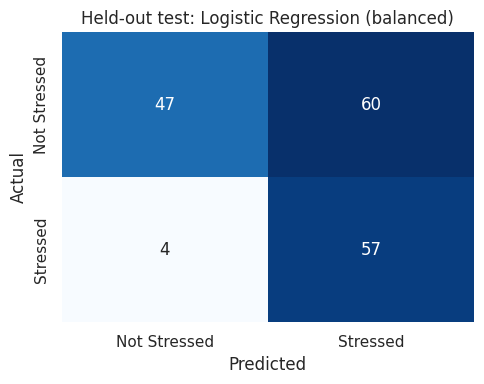

In [64]:
# Final evaluation on later, held-out target quarters (one assessment after selection).
X_train = train_df[model_features].copy()
y_train = train_df["stress_next_q"].astype(int)
X_test = test_df[model_features].copy()
y_test = test_df["stress_next_q"].astype(int)

if selected_model_name == "Persistence Baseline":
    y_pred = test_df["stress"].astype(int).to_numpy()
    y_score = y_pred.astype(float)  # Binary baseline score; AUC is descriptive only.
else:
    selected_estimator = fit_candidate(selected_model_name, X_train, y_train)
    y_pred = selected_estimator.predict(X_test)
    y_score = selected_estimator.predict_proba(X_test)[:, 1]

heldout_results = pd.DataFrame([{
    "Model": selected_model_name,
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score) if y_test.nunique() == 2 else np.nan,
}]).set_index("Model")
print("Held-out results (not used to select the approach):")
display(heldout_results.round(3))

heldout_cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(heldout_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Not Stressed", "Stressed"],
            yticklabels=["Not Stressed", "Stressed"], ax=ax)
ax.set(title=f"Held-out test: {selected_model_name}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout()
plt.show()


### Train the deployment model and predict the next quarter


In [65]:
# Refit the selected approach on all labelled observations for deployment.
X_final = model_df[model_features].copy()
y_final = model_df["stress_next_q"].astype(int)
if selected_model_name == "Persistence Baseline":
    # The dashboard expects a fitted model with predict/predict_proba and feature names.
    # A baseline cannot be represented by a normal fitted sklearn model: it uses
    # the current-quarter stress flag rather than the ten numerical predictors.
    # Stop with a clear instruction instead of exporting an incompatible artifact.
    raise RuntimeError(
        "Persistence Baseline won validation. Update the dashboard to use the "
        "current-quarter stress flag before exporting a deployment model."
    )
final_model = fit_candidate(selected_model_name, X_final, y_final)
print(f"Final {selected_model_name} model trained on {len(X_final)} labelled observations.")


Final Logistic Regression (balanced) model trained on 684 labelled observations.


In [66]:
#Predict Next-Quarter Industry Stress

# Select the latest available quarter with complete features
prediction_df = df_features.dropna(
    subset=model_features
).copy()

prediction_df["quarter"] = pd.PeriodIndex(
    prediction_df["quarter"], freq="Q"
)

latest_quarter = prediction_df["quarter"].max()

latest_data = (
    prediction_df[
        prediction_df["quarter"] == latest_quarter
    ]
    .sort_values("industry")
    .copy()
)

# Predict stress probabilities and classifications
latest_data["Model Stress Score"] = final_model.predict_proba(
    latest_data[model_features]
)[:, 1]

latest_data["Predicted Stress"] = final_model.predict(
    latest_data[model_features]
)

# Prepare results
prediction_results = latest_data[
    ["industry", "Model Stress Score", "Predicted Stress"]
].copy()

prediction_results["Model Stress Score"] = (
    prediction_results["Model Stress Score"] * 100
).round(1)

prediction_results["Predicted Stress"] = (
    prediction_results["Predicted Stress"]
    .map({1: "Stressed", 0: "Not Stressed"})
)

prediction_results = prediction_results.sort_values(
    "Model Stress Score", ascending=False
)

print(f"Latest Available Quarter: {latest_quarter}")
print(f"Predicted Quarter: {latest_quarter + 1}")

display(prediction_results)


Latest Available Quarter: 2026Q2
Predicted Quarter: 2026Q3


,industry,Model Stress Score,Predicted Stress
139,administrative and support services,87.2,Stressed
69,accommodation and food services,80.8,Stressed
769,transportation and storage,78.1,Stressed
419,information and communications,77.5,Stressed
209,"community, social and personal services",74.2,Stressed
629,professional services,63.1,Stressed
839,wholesale and retail trade,62.7,Stressed
349,financial and insurance services,60.2,Stressed
559,others,55.2,Stressed
699,real estate services,47.3,Not Stressed


## 8. Dashboard exports

The final section exports three files for the Streamlit application: the fitted model, latest complete-quarter model features, and historical indicator values. The application calculates its own screening scores from these exports. Dashboard results reflect the notebook only when the deployed model and data files have been updated from the same execution.

In [67]:
# Export only the three files used to supply the deployed dashboard.
joblib.dump(final_model, "labour_stress_model.joblib")

dashboard_df = latest_data[["industry", "quarter"] + model_features].copy()
dashboard_df["quarter"] = dashboard_df["quarter"].astype(str)
dashboard_df.to_csv("dashboard_data.csv", index=False)

historical_export = df_master.copy()
historical_export["quarter"] = historical_export["quarter"].astype(str)
historical_export.to_csv("historical_labour_data.csv", index=False)

print("Saved: labour_stress_model.joblib, dashboard_data.csv, historical_labour_data.csv")
print(f"Dashboard feature quarter: {latest_quarter}; industries: {len(dashboard_df)}")

print("Note: this snapshot can only forecast one quarter after the latest complete source quarter.")


Saved: labour_stress_model.joblib, dashboard_data.csv, historical_labour_data.csv
Dashboard feature quarter: 2026Q2; industries: 12
Note: this snapshot can only forecast one quarter after the latest complete source quarter.
